In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,roc_auc_score, confusion_matrix, classification_report,roc_curve, precision_recall_curve)


In [2]:
df = pd.read_csv('/content/aug_train.csv')
print("shape:",df.shape)
print()
df.info()
print()
df.describe()

shape: (19158, 14)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int

,enrollee_id,city_development_index,training_hours,target
count,19158.000000,19158.000000,19158.000000,19158.000000
mean,16875.358179,0.828848,65.366896,0.249348
std,9616.292592,0.123362,60.058462,0.432647
min,1.000000,0.448000,1.000000,0.000000
25%,8554.250000,0.740000,23.000000,0.000000
50%,16982.500000,0.903000,47.000000,0.000000
75%,25169.750000,0.920000,88.000000,0.000000
max,33380.000000,0.949000,336.000000,1.000000


In [3]:
df['target'].value_counts()
df['target'].value_counts(normalize=True) * 100


,proportion
target,
0.0,75.065247
1.0,24.934753


In [4]:
missing = df.isnull().sum()
missing_table = pd.DataFrame({'missing': missing})
missing_table = missing_table[missing_table['missing'] > 0].sort_values('missing',ascending=False)
print(missing_table)

print()
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate columns:", df.T.duplicated().sum())


                     missing
company_type            6140
company_size            5938
gender                  4508
major_discipline        2813
education_level          460
last_new_job             423
enrolled_university      386
experience                65

Duplicate rows: 0
Duplicate columns: 0


In [5]:
for col in ['company_size', 'company_type', 'gender', 'major_discipline']:
    rate_missing = df.loc[df[col].isna(), 'target'].mean()
    rate_present = df.loc[df[col].notna(), 'target'].mean()
    print(f"{col:<16} target rate if missing: {rate_missing:.1%}   target rate if filled in: {rate_present:.1%}")

company_size     target rate if missing: 40.6%   target rate if filled in: 17.9%
company_type     target rate if missing: 38.8%   target rate if filled in: 18.4%
gender           target rate if missing: 30.8%   target rate if filled in: 23.1%
major_discipline target rate if missing: 19.5%   target rate if filled in: 25.9%


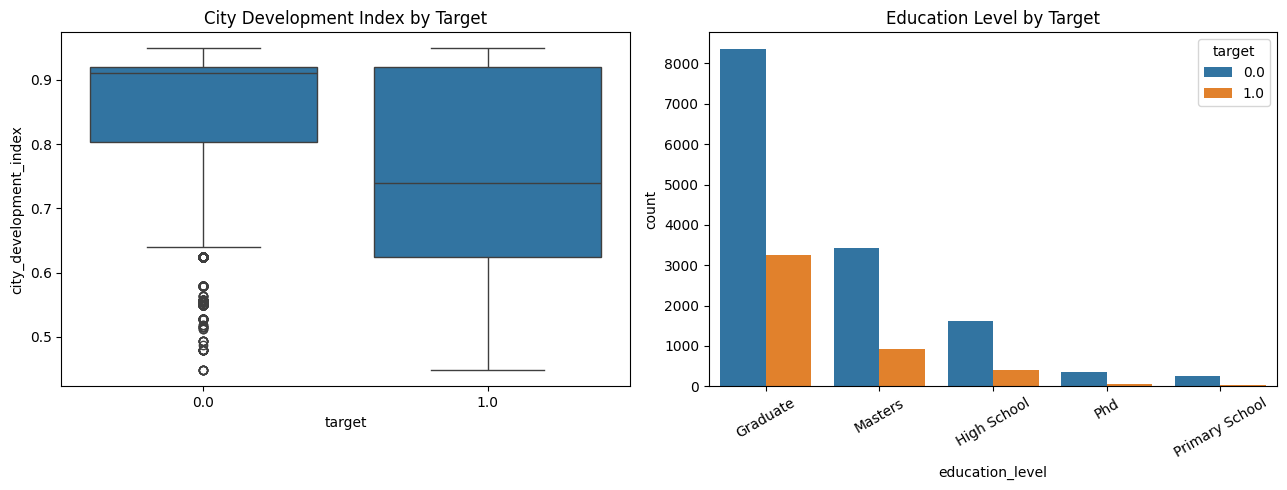

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x='target', y='city_development_index', ax=axes[0])
axes[0].set_title('City Development Index by Target')

sns.countplot(data=df, x='education_level', hue='target', ax=axes[1])
axes[1].set_title('Education Level by Target')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

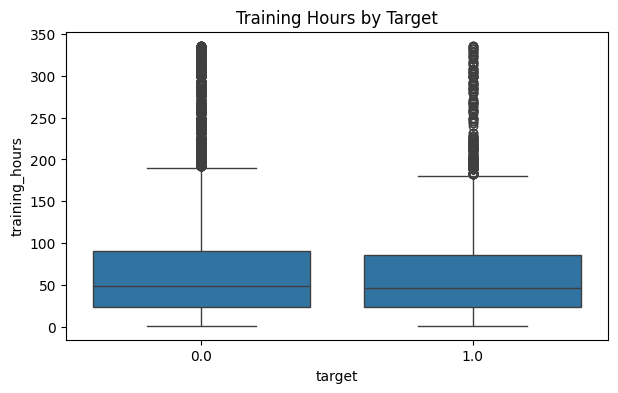


Rows above the upper outlier fence: 984 (5.1% of the data)


In [22]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='target', y='training_hours')
plt.title('Training Hours by Target')
plt.show()

q1 = df['training_hours'].quantile(0.25)
q3 = df['training_hours'].quantile(0.75)
upper_fence = q3 + 1.5 * (q3 - q1)
outlier_count = (df['training_hours'] > upper_fence).sum()
print()
print(f"Rows above the upper outlier fence: {outlier_count} ({outlier_count / len(df):.1%} of the data)")

In [7]:
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{'='*50}")
    print(col)
    print(df[col].value_counts(dropna=False))


city
city
city_103    4355
city_21     2702
city_16     1533
city_114    1336
city_160     845
            ... 
city_111       3
city_129       3
city_121       3
city_140       1
city_171       1
Name: count, Length: 123, dtype: int64

gender
gender
Male      13221
NaN        4508
Female     1238
Other       191
Name: count, dtype: int64

relevent_experience
relevent_experience
Has relevent experience    13792
No relevent experience      5366
Name: count, dtype: int64

enrolled_university
enrolled_university
no_enrollment       13817
Full time course     3757
Part time course     1198
NaN                   386
Name: count, dtype: int64

education_level
education_level
Graduate          11598
Masters            4361
High School        2017
NaN                 460
Phd                 414
Primary School      308
Name: count, dtype: int64

major_discipline
major_discipline
STEM               14492
NaN                 2813
Humanities           669
Other                381
Business Degree 

In [8]:
TOP_CITIES = df['city'].value_counts().head(5).index

EDU_MAP = {'Primary School': 1, 'High School': 2, 'Graduate': 3, 'Masters': 4, 'Phd': 5}
SIZE_MAP = {'Unknown': 0, '<10': 1, '10/49': 2, '50-99': 3, '100-500': 4,
            '500-999': 5, '1000-4999': 6, '5000-9999': 7, '10000+': 8}


def clean(data):
    d = data.copy()

    d = d.drop(columns=['enrollee_id', 'gender'])

    d['is_unemployed'] = (d['company_size'].isna() & d['company_type'].isna()).astype(int)

    for col in ['enrolled_university', 'major_discipline', 'company_size', 'company_type']:
        d[col] = d[col].fillna('Unknown')

    d['experience'] = d['experience'].replace({'<1': '0', '>20': '21'})
    d['experience'] = pd.to_numeric(d['experience'], errors='coerce')

    d['last_new_job'] = d['last_new_job'].replace({'never': '0', '>4': '5'})
    d['last_new_job'] = pd.to_numeric(d['last_new_job'], errors='coerce')

    d['education_level'] = d['education_level'].map(EDU_MAP)
    d['company_size'] = d['company_size'].map(SIZE_MAP)

    d['relevent_experience'] = (d['relevent_experience'] == 'Has relevent experience').astype(int)

    d['city'] = d['city'].where(d['city'].isin(TOP_CITIES), 'Other')

    return d


df_clean = clean(df)
print("Cleaned shape:", df_clean.shape)
print()
print(df_clean.isna().sum()[df_clean.isna().sum() > 0])
df_clean.head()

Cleaned shape: (19158, 13)

education_level    460
experience          65
last_new_job       423
dtype: int64


,city,city_development_index,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target,is_unemployed
0,city_103,0.920,1,no_enrollment,3.0,STEM,21.0,0,Unknown,1.0,36,1.0,1
1,Other,0.776,0,no_enrollment,3.0,STEM,15.0,3,Pvt Ltd,5.0,47,0.0,0
2,city_21,0.624,0,Full time course,3.0,STEM,5.0,0,Unknown,0.0,83,0.0,1
3,Other,0.789,0,Unknown,3.0,Business Degree,0.0,0,Pvt Ltd,0.0,52,1.0,0
4,Other,0.767,1,no_enrollment,4.0,STEM,21.0,3,Funded Startup,4.0,8,0.0,0


In [9]:
X = df_clean.drop(columns=['target'])
y = df_clean['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_train = X_train.copy()
X_test = X_test.copy()

print(f"Train: {X_train.shape[0]:,} rows")
print(f"Test:  {X_test.shape[0]:,} rows")

Train: 13,410 rows
Test:  5,748 rows


In [10]:
fill_values = {}
for col in ['experience', 'last_new_job', 'education_level']:
    fill_values[col] = X_train[col].median()
    X_train[col] = X_train[col].fillna(fill_values[col])
    X_test[col] = X_test[col].fillna(fill_values[col])

In [11]:
categorical_cols = ['city', 'enrolled_university', 'major_discipline', 'company_type']
numeric_cols = ['city_development_index', 'education_level', 'experience', 'company_size',
                'last_new_job', 'training_hours', 'relevent_experience', 'is_unemployed']

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)


train_encoded = encoder.fit_transform(X_train[categorical_cols])
test_encoded = encoder.transform(X_test[categorical_cols])

train_encoded = pd.DataFrame(train_encoded, columns=encoder.get_feature_names_out(categorical_cols), index=X_train.index)
test_encoded = pd.DataFrame(test_encoded, columns=encoder.get_feature_names_out(categorical_cols), index=X_test.index)

X_train_final = pd.concat([X_train[numeric_cols], train_encoded], axis=1)
X_test_final = pd.concat([X_test[numeric_cols], test_encoded], axis=1)

print("Final training shape:", X_train_final.shape)
X_train_final.head()

Final training shape: (13410, 32)


,city_development_index,education_level,experience,company_size,last_new_job,training_hours,relevent_experience,is_unemployed,city_Other,city_city_103,...,major_discipline_Other,major_discipline_STEM,major_discipline_Unknown,company_type_Early Stage Startup,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,company_type_Unknown
8253,0.624,4.0,7.0,1,1.0,40,1,0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
10067,0.920,3.0,19.0,4,2.0,48,1,0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1851,0.624,3.0,5.0,0,1.0,135,1,1,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4139,0.682,3.0,2.0,0,0.0,45,0,1,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2473,0.624,2.0,10.0,0,0.0,68,0,1,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [12]:
param_grid = {'max_depth': range(2, 11)}

grid_search = GridSearchCV(DecisionTreeClassifier(criterion='gini', random_state=42), param_grid, cv=5)
grid_search.fit(X_train_final, y_train)

best_depth = grid_search.best_params_['max_depth']
print(f"Best max_depth: {best_depth}")

model = DecisionTreeClassifier(criterion='gini', max_depth=best_depth, random_state=42)
model.fit(X_train_final, y_train)

y_pred = model.predict(X_test_final)

Best max_depth: 7


In [13]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

Accuracy: 0.78


Confusion Matrix:
[[3689  611]
 [ 631  817]]


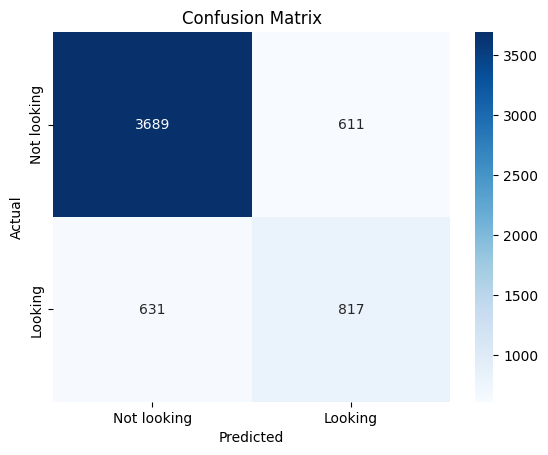

In [14]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Not looking', 'Looking'], yticklabels=['Not looking', 'Looking'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [15]:
print(classification_report(y_test, y_pred, target_names=['Not looking', 'Looking to move']))

                 precision    recall  f1-score   support

    Not looking       0.85      0.86      0.86      4300
Looking to move       0.57      0.56      0.57      1448

       accuracy                           0.78      5748
      macro avg       0.71      0.71      0.71      5748
   weighted avg       0.78      0.78      0.78      5748



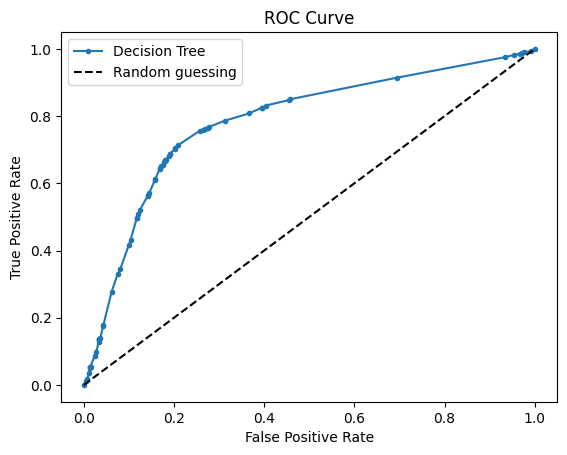


AUC Score: 0.78


In [16]:
y_prob = model.predict_proba(X_test_final)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr, marker='.', label='Decision Tree')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

auc_score = roc_auc_score(y_test, y_prob)
print()
print(f"AUC Score: {auc_score:.2f}")

city_development_index                  0.5017
is_unemployed                           0.2189
major_discipline_Unknown                0.0783
experience                              0.0373
training_hours                          0.0307
city_city_103                           0.0247
city_city_160                           0.0205
last_new_job                            0.0187
company_size                            0.0160
enrolled_university_Full time course    0.0099
dtype: float64



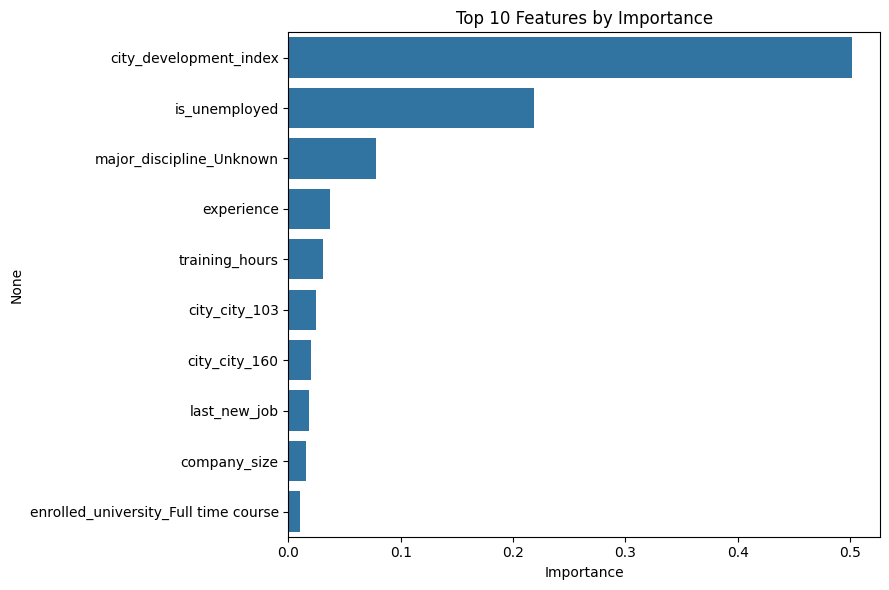

In [20]:
importances = pd.Series(model.feature_importances_, index=X_train_final.columns).sort_values(ascending=False)
print(importances.head(10).round(4))
print()

plt.figure(figsize=(9, 6))
sns.barplot(x=importances.head(10).values, y=importances.head(10).index)
plt.title('Top 10 Features by Importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

In [18]:
new_data = pd.read_csv('/content/aug_test.csv')
candidate_ids = new_data['enrollee_id']

new_clean = clean(new_data)

for col, fill_value in fill_values.items():
    new_clean[col] = new_clean[col].fillna(fill_value)

new_encoded = encoder.transform(new_clean[categorical_cols])
new_encoded = pd.DataFrame(new_encoded, columns=encoder.get_feature_names_out(categorical_cols), index=new_clean.index)

new_final = pd.concat([new_clean[numeric_cols], new_encoded], axis=1)

new_pred = model.predict(new_final)
new_prob = model.predict_proba(new_final)[:, 1]

In [19]:
results = pd.DataFrame({
    'enrollee_id': candidate_ids,
    'priority_score': new_prob.round(3),
    'recommendation': np.where(new_pred == 1, 'Advance to next stage', 'Lower priority')
}).sort_values('priority_score', ascending=False).reset_index(drop=True)

print(f"Scored {len(results):,} candidates.")
print(f"{(results['recommendation'] == 'Advance to next stage').sum():,} recommended to advance.")
results.head(15)

Scored 2,129 candidates.
534 recommended to advance.


,enrollee_id,priority_score,recommendation
0,18369,1.000,Advance to next stage
1,7012,1.000,Advance to next stage
2,14832,1.000,Advance to next stage
3,16336,1.000,Advance to next stage
4,16079,1.000,Advance to next stage
5,11842,1.000,Advance to next stage
6,14398,1.000,Advance to next stage
7,29710,1.000,Advance to next stage
8,11063,1.000,Advance to next stage
9,9752,1.000,Advance to next stage
